Features:
RETRIEVAL FROM TTNN
----
two_tower_score
two_tower_rank
two_tower_score_z
DONE

USER
----
user_rating_mean
user_rating_std
user_rating_count
DONE


MOVIE
-----
runtime (TMDB)
popularity (TMDB)
release_year - DONE
vote_count (TMDB)



USER × MOVIE
------------
genre_affinity - DONE
decade_affinity - DONE
content_cosine_similarity
language_affinity (waiting for user features)

In [64]:
import numpy as np
import pandas as pd
from xgboost import XGBRanker
import xgboost as xgb
from sklearn.metrics import ndcg_score

In [65]:
# from recommender script 
train_candidate_preds_ranked  = pd.read_parquet("../data/train_candidate_preds_ranked.parquet")
test_candidate_preds_ranked  = pd.read_parquet("../data/test_candidate_preds_ranked.parquet")

# ['userId', 'movieId', 'rating', 'user_avg_rating', 'user_std_rating', 'user_count_rating', 'movie_Release_Year', 'genre_affinity', 'decade_affinity', 'predicted_rating', 'user_rank', 'z_score']

In [ ]:
# split by user 
train_df = (train_candidate_preds_ranked.sort_values(["userId"]).reset_index(drop=True))
test_df = test_candidate_preds_ranked.sort_values(by=["userId", "user_rank"]).reset_index(drop=True)

X_train = train_df[[
    "user_avg_rating",
    "user_std_rating",
    "user_count_rating",
    "movie_Release_Year",
    "genre_affinity",
    "decade_affinity",
    "predicted_rating",
    "user_rank",
    "z_score"
]]

X_test = test_df[[
    "user_avg_rating",
    "user_std_rating",
    "user_count_rating",
    "movie_Release_Year",
    "genre_affinity",
    "decade_affinity",
    "predicted_rating",
    "user_rank",
    "z_score"
]]

def z_to_relevance(z):
    if z > 1:
        return 3  #high link
    elif z > 0.5:
        return 2  #medium link
    elif z > 0:
        return 1  #above avergae
    else:
        return 0 #below average

z_train = (train_df["rating"] - train_df["user_avg_rating"]) / train_df["user_std_rating"]
train_df["relevance"] = z_train.apply(z_to_relevance)

z_test = (test_df["rating"] - test_df["user_avg_rating"]) / test_df["user_std_rating"]
test_df["relevance"] = z_test.apply(z_to_relevance)


In [67]:
model = xgb.XGBRanker(
    objective="rank:ndcg",
    eval_metric="ndcg@10",
    n_estimators=100,
    random_state=42
)
model.fit(X_train, train_df["relevance"], qid=train_df["userId"])

test_df["xgb_score"] = model.predict(X_test)

test_df["xgb_rank"] = (
    test_df
    .groupby("userId")["xgb_score"]
    .rank(method="first", ascending=False)
)

In [ ]:
user_ndcgs = []

for user_id, user_data in test_df.groupby("userId"):

    # True relevance: 0, 1, 2, 3
    y_true = user_data["relevance"].to_numpy().reshape(1, -1)

    # XGBRanker's predicted ranking score
    y_score = user_data["xgb_score"].to_numpy().reshape(1, -1)

    ndcg = ndcg_score(
        y_true,
        y_score,
        k=10
    )

    user_ndcgs.append(ndcg)

mean_ndcg = np.mean(user_ndcgs)

print(f"XGBRanker NDCG@10: {mean_ndcg:.4f}")

XGBRanker NDCG@10: 0.6171


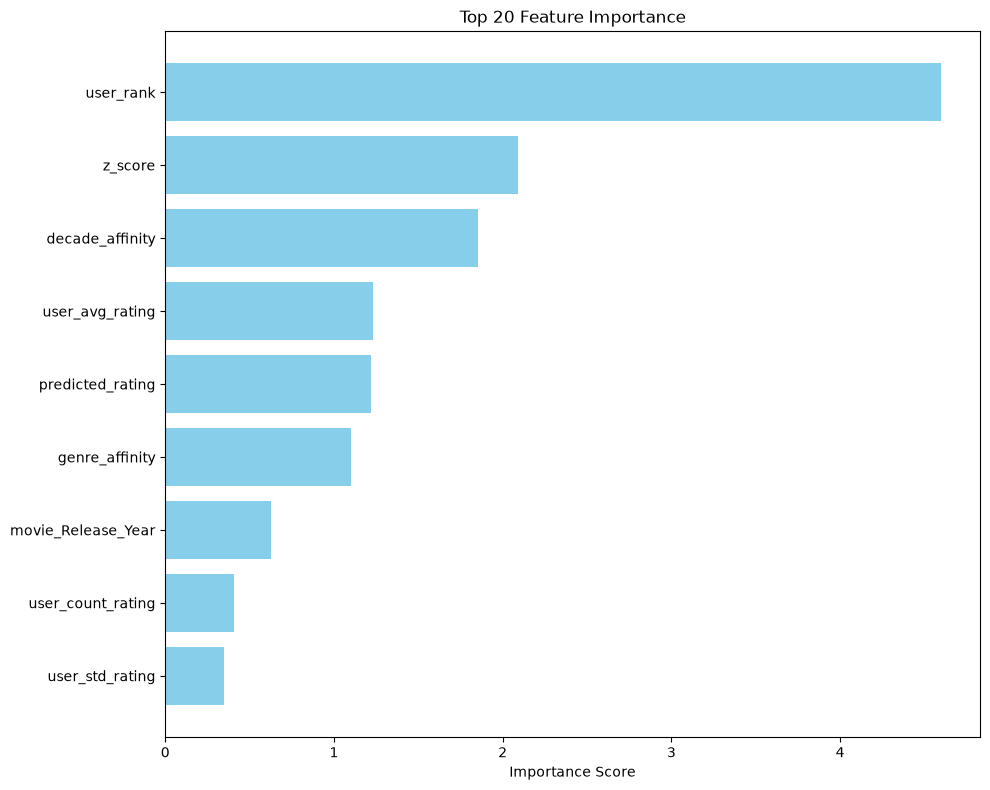

In [69]:
#feature importance vis
import matplotlib.pyplot as plt

importance = model.get_booster().get_score(importance_type='gain')

importance_df = pd.DataFrame({
    'Feature': list(importance.keys()),
    'Importance': list(importance.values())
}).sort_values(by='Importance', ascending=False)

top_n = 20
plt.figure(figsize=(10, 8))
plt.barh(
    importance_df['Feature'].head(top_n)[::-1],
    importance_df['Importance'].head(top_n)[::-1],
    color='skyblue'
)
plt.xlabel('Importance Score')
plt.title(f'Top {top_n} Feature Importance')
plt.tight_layout()
plt.show()

In [70]:
model.save_model("../models/xgboostranker_model.json")